# What Makes a Chess Puzzle Hard? Predicting Lichess Puzzle Difficulty

**Question:** Lichess rates each chess puzzle's difficulty from how real players succeed or fail on it. Can we predict that rating from the puzzle itself (the position and its solution), and which properties make a puzzle hard?

**File needed in the same folder as this notebook:** `lichess_puzzles_sample.csv`. Run with Run → Run All Cells (under a minute).

## 1. Setup

In [1]:
# If you get ModuleNotFoundError, run this once and restart the kernel:
# %pip install pandas numpy matplotlib seaborn scikit-learn chess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import chess          # python-chess: reads chess positions and moves

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42     # fixed seed so results are reproducible

## 2. Data

**Source:** the Lichess open puzzle database (https://database.lichess.org/#puzzles), public domain (CC0). We use the first 51,200 puzzles by puzzle ID from a public mirror of the September 2022 database (github.com/mcognetta/lichess-combined-puzzle-game-db). Puzzle IDs are random codes, so this behaves like a random sample.

In [2]:
df = pd.read_csv("lichess_puzzles_sample.csv")
print(df.shape)
df.head()

(51200, 10)


,PuzzleId,FEN,Moves,Rating,RatingDeviation,Popularity,NbPlays,Themes,GameUrl,OpeningFamily
0,002rd,r6k/q1pb1p1p/1b3Pr1/p1ppP2Q/3P2p1/4B3/PP2NRPP/...,d7e6 e2f4 c5d4 f4g6 f7g6 h5h6,1829,255,100,9,crushing kingsideAttack long middlegame pin,https://lichess.org/NcD6lul8/black#50,NaN
1,00K8j,r2q2kr/p4pp1/4b2p/n1Qn4/5B2/4P3/PP3PPP/2KR1BNR...,f4c7 d8c7 c5c7 d5c7,1428,75,85,185,advantage opening short,https://lichess.org/AiNXhpcc#27,Queens_Gambit_Declined
2,00FHO,8/1pp5/p2p3p/3P1Pk1/P3K1P1/1P5R/8/2r5 w - - 1 39,e4f3 c1c3 f3g2 c3h3 g2h3 h6h5 g4h5 g5h5,2233,112,100,19,crushing endgame rookEndgame veryLong,https://lichess.org/0KBMAMQh#77,NaN
3,00H2L,8/8/2p2p2/p4P1p/Pk5P/4K1P1/8/8 w - - 1 39,e3d3 c6c5 d3e2 c5c4 g3g4 h5g4,2351,112,85,26,crushing endgame long pawnEndgame quietMove,https://lichess.org/UMoEkwn0#77,NaN
4,00HEx,b7/5pk1/R3pn1p/8/3NP3/5P2/6PP/2rB2K1 w - - 1 31,a6a8 c1d1 g1f2 d1d4,1490,486,100,1,crushing endgame fork hangingPiece short,https://lichess.org/Kl5pBLfs#61,NaN


| Column | Meaning |
|---|---|
| `FEN` | The board position in standard chess notation |
| `Moves` | The moves (e.g. `e2e4` = from e2 to e4). **The first move is the opponent's** and sets up the puzzle; the solver must find the rest |
| `Rating` | **Target:** puzzle difficulty, on the same scale as player ratings |
| `RatingDeviation` | How uncertain the rating is (high = few people have tried it) |
| `Popularity`, `NbPlays` | Player votes and number of attempts |
| `Themes`, `GameUrl`, `PuzzleId`, `OpeningFamily` | Tags, source game, ID, opening name |

### 2.1 Basic checks

In [3]:
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate puzzles:", df.PuzzleId.duplicated().sum())
game_ids = df.GameUrl.str.extract(r"lichess.org/(\w{8})")[0]
print("Puzzles sharing a source game:", game_ids.duplicated(keep=False).sum())

Missing values:
 PuzzleId               0
FEN                    0
Moves                  0
Rating                 0
RatingDeviation        0
Popularity             0
NbPlays                0
Themes                 0
GameUrl                0
OpeningFamily      40675
dtype: int64 

Duplicate puzzles: 0
Puzzles sharing a source game: 0


**Observations:** nothing is missing except `OpeningFamily` (not used). There are no duplicates, and every puzzle comes from a different game, so near-identical positions can't end up in both the training and test data.

### 2.2 Label quality: removing unreliable ratings

A rating only becomes accurate after many people have tried the puzzle. `RatingDeviation` measures that uncertainty.

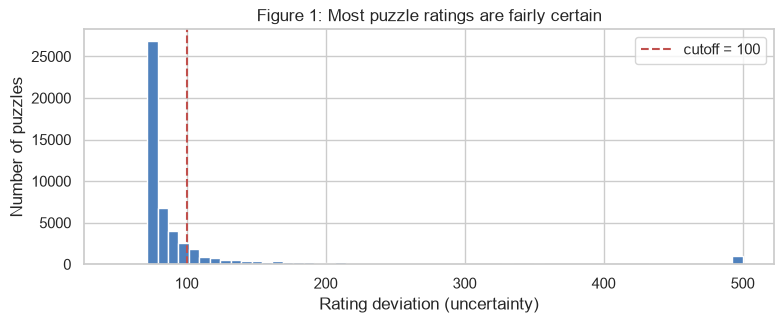

Keeping 39,855 of 51,200 puzzles
Median attempts, kept: 382.0 | dropped: 15.0


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(df.RatingDeviation, bins=60, color="#4f81bd")
ax.axvline(100, color="#c0504d", ls="--", label="cutoff = 100")
ax.set_xlabel("Rating deviation (uncertainty)"); ax.set_ylabel("Number of puzzles")
ax.set_title("Figure 1: Most puzzle ratings are fairly certain"); ax.legend()
plt.tight_layout(); plt.show()

reliable = df.RatingDeviation <= 100
print(f"Keeping {reliable.sum():,} of {len(df):,} puzzles")
print("Median attempts, kept:", df.NbPlays[reliable].median(), "| dropped:", df.NbPlays[~reliable].median())
df = df[reliable].reset_index(drop=True)

**Decision:** keep puzzles with rating deviation ≤ 100. The dropped ones have a median of only 15 attempts, so their ratings are mostly guesses. About 40,000 puzzles remain.

## 3. Features

A model needs numbers, so for each puzzle we compute six features from the board and its solution, describing what the solver faces after the opponent's setup move. All six use only the puzzle itself. We deliberately don't use `Popularity`, `NbPlays`, or `RatingDeviation`, which are only known after people play the puzzle (data leakage).

| Feature | Meaning |
|---|---|
| `solution_moves` | How many moves the solver has to find |
| `key_is_check` | 1 if the solver's first move gives check |
| `key_is_capture` | 1 if the first move captures a piece (if both are 0, it's a "quiet" move) |
| `n_checks_available` | How many of the solver's legal moves give check |
| `n_captures_available` | How many of the solver's legal moves capture something |
| `material_sacrificed` | Material the solver gives up during the solution (pawn = 1, knight/bishop = 3, rook = 5, queen = 9). 0 = no sacrifice |

In [5]:
VALUES = {chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3, chess.ROOK: 5, chess.QUEEN: 9, chess.KING: 0}

def material_balance(board, color):
    """Material of `color` minus material of the opponent."""
    total = 0
    for piece in board.piece_map().values():
        total += VALUES[piece.piece_type] * (1 if piece.color == color else -1)
    return total

def puzzle_features(fen, moves_str):
    moves = moves_str.split()
    board = chess.Board(fen)
    board.push_uci(moves[0])                    # opponent's setup move: now it's the solver's turn
    solver = board.turn
    legal = list(board.legal_moves)
    key = chess.Move.from_uci(moves[1])         # the solver's first move

    # Sacrifice: play through the solution and find the lowest material balance after each
    # solver move (checking after the solver's moves ignores simple trades that are taken back)
    line = board.copy()
    start = material_balance(line, solver)
    lowest = start
    rest = moves[1:]
    for i, uci in enumerate(rest):
        line.push_uci(uci)
        if i % 2 == 0 or i == len(rest) - 1:
            lowest = min(lowest, material_balance(line, solver))

    return {"solution_moves": len(moves[1::2]),
            "key_is_check": int(board.gives_check(key)),
            "key_is_capture": int(board.is_capture(key)),
            "n_checks_available": sum(board.gives_check(m) for m in legal),
            "n_captures_available": sum(board.is_capture(m) for m in legal),
            "material_sacrificed": start - lowest}

X = pd.DataFrame([puzzle_features(f, m) for f, m in zip(df.FEN, df.Moves)])
y = df.Rating
X.describe().round(2)

,solution_moves,key_is_check,key_is_capture,n_checks_available,n_captures_available,material_sacrificed
count,39855.00,39855.00,39855.00,39855.00,39855.00,39855.00
mean,2.36,0.53,0.42,1.87,2.52,0.32
std,0.83,0.50,0.49,1.79,1.76,1.12
min,1.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,0.00,0.00,1.00,1.00,0.00
50%,2.00,1.00,0.00,1.00,2.00,0.00
75%,3.00,1.00,1.00,3.00,4.00,0.00
max,13.00,1.00,1.00,15.00,11.00,11.00


## 4. Exploratory data analysis

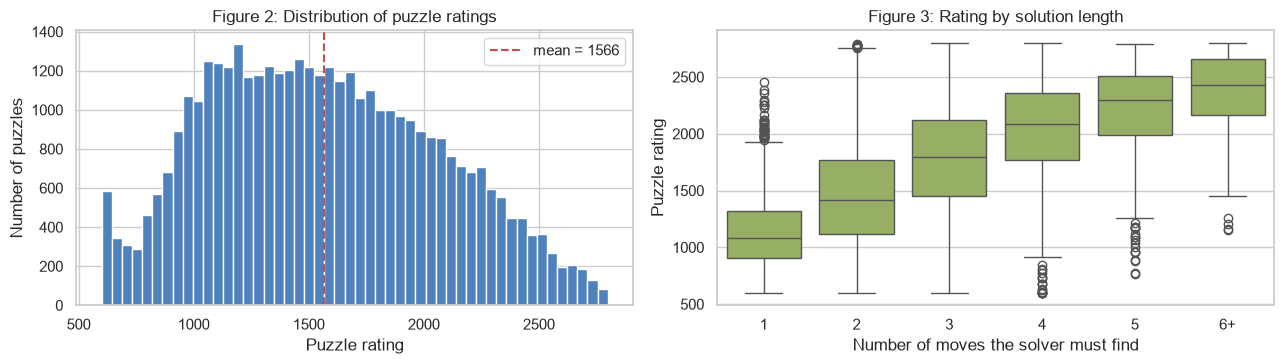

solution_moves       1        2       3       4       5       6
mean            1123.0   1461.0  1781.0  2041.0  2205.0  2361.0
count           2833.0  24068.0  9925.0  2181.0   573.0   275.0


In [6]:
data = pd.concat([df, X], axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

axes[0].hist(y, bins=50, color="#4f81bd")
axes[0].axvline(y.mean(), color="#c0504d", ls="--", label=f"mean = {y.mean():.0f}")
axes[0].set_xlabel("Puzzle rating"); axes[0].set_ylabel("Number of puzzles")
axes[0].set_title("Figure 2: Distribution of puzzle ratings"); axes[0].legend()

length = data.solution_moves.clip(upper=6)
sns.boxplot(x=length, y=y, ax=axes[1], color="#9bbb59")
axes[1].set_xticks(range(6)); axes[1].set_xticklabels(["1", "2", "3", "4", "5", "6+"])
axes[1].set_xlabel("Number of moves the solver must find"); axes[1].set_ylabel("Puzzle rating")
axes[1].set_title("Figure 3: Rating by solution length")
plt.tight_layout(); plt.show()
print(data.groupby(length).Rating.agg(["mean", "count"]).round(0).T)

**Observations:**
- Ratings are spread fairly evenly around a mean of 1,566 (standard deviation about 500), with a small pile-up at the minimum rating (about 600). There's no extreme imbalance, so average error in rating points is a meaningful metric.
- **Longer solutions are harder:** 1-move puzzles average about 1,120, 2-move about 1,460, 3-move about 1,780, and 4-move about 2,040, so each extra move adds roughly 300 points. But the boxes overlap a lot: 2-move puzzles alone range from 600 to about 2,800. Length is the clearest signal, but it can't be the only one.

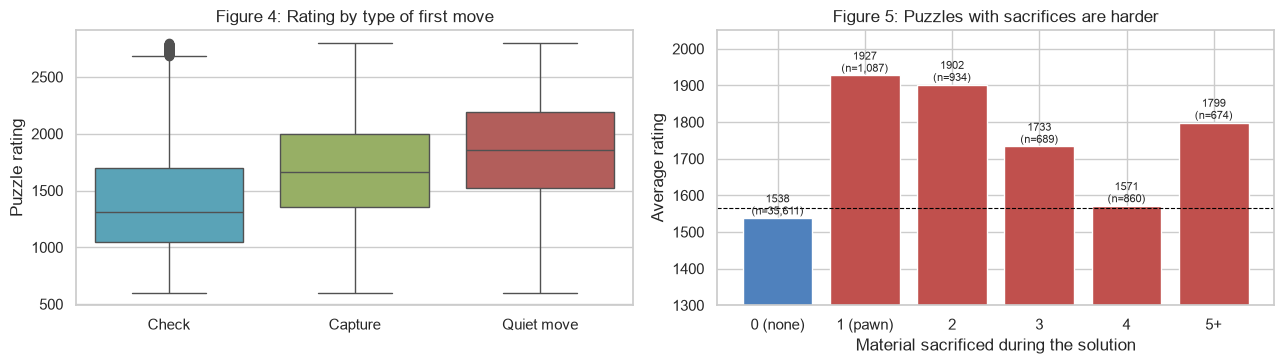

              mean  count
Capture     1677.0   9677
Check       1396.0  21265
Quiet move  1848.0   8913


In [7]:
move_type = np.select([data.key_is_check == 1, data.key_is_capture == 1], ["Check", "Capture"], "Quiet move")
sac = data.material_sacrificed.clip(upper=5)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(x=move_type, y=y, order=["Check", "Capture", "Quiet move"], ax=axes[0],
            hue=move_type, hue_order=["Check", "Capture", "Quiet move"],
            palette=["#4bacc6", "#9bbb59", "#c0504d"], legend=False)
axes[0].set_ylabel("Puzzle rating"); axes[0].set_title("Figure 4: Rating by type of first move")

means = y.groupby(sac).mean()
labels = ["0 (none)", "1 (pawn)", "2", "3", "4", "5+"]
axes[1].bar(labels, means.values, color=["#4f81bd"] + ["#c0504d"] * 5)
axes[1].axhline(y.mean(), color="black", ls="--", lw=0.8)
axes[1].set_ylim(1300, 2050)
axes[1].set_xlabel("Material sacrificed during the solution"); axes[1].set_ylabel("Average rating")
axes[1].set_title("Figure 5: Puzzles with sacrifices are harder")
for i, (m, n) in enumerate(zip(means.values, sac.value_counts().sort_index().values)):
    axes[1].text(i, m + 10, f"{m:.0f}\n(n={n:,})", ha="center", fontsize=8)
plt.tight_layout(); plt.show()
print(y.groupby(move_type).agg(["mean", "count"]).round(0))

**Observations:**
- **Checks are the easiest first moves** (average 1,396), captures are in the middle (1,677), and **quiet moves are the hardest** (1,848). This matches the chess habit of looking at checks first.
- **Puzzles with a sacrifice are harder** (all sacrifice groups are above the 1,538 average for puzzles without one), and pawn sacrifices are the hardest (1,927). The relationship isn't a straight line: 4-point sacrifices are close to average. A linear model can't represent that, which is one reason to also try a random forest.

## 5. Preprocessing and setup

| Step | What we do | Why |
|---|---|---|
| Unreliable labels | Removed puzzles with rating deviation > 100 (Section 2.2) | Too few attempts for a trustworthy rating |
| Leakage | `Popularity`, `NbPlays`, `RatingDeviation` not used as features | Only known after people play the puzzle |
| Features | Six numeric features computed from each position (Section 3) | Models need numbers, not board diagrams |
| Missing values / encoding | None needed | No missing values; all six features are already numbers |
| Scaling | Not needed | Linear regression without a penalty and random forests give the same predictions whether or not features are scaled |
| Split | 70% train / 15% validation / 15% test, stratified by rating range | Train fits the models, validation chooses settings, and the test set is used **once** at the end |

In [8]:
from sklearn.model_selection import train_test_split

bins = pd.qcut(y, 10, labels=False)   # stratify so each split covers the full range of difficulty
idx_train, idx_temp = train_test_split(X.index, test_size=0.30, stratify=bins, random_state=RANDOM_STATE)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=bins[idx_temp], random_state=RANDOM_STATE)
X_train, X_val, X_test = X.loc[idx_train], X.loc[idx_val], X.loc[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
print(f"Train: {len(idx_train):,}  Validation: {len(idx_val):,}  Test: {len(idx_test):,}")

Train: 27,898  Validation: 5,978  Test: 5,979


**Metrics:**
- **MAE (mean absolute error):** average number of rating points a prediction is off by.
- **R²:** share of the variation in difficulty the model explains (0 = no better than guessing the average, 1 = perfect).

**Baseline:** always predict the average training rating. A model is only useful if it beats this.

In [9]:
from sklearn.metrics import mean_absolute_error, r2_score

def evaluate(name, y_true, y_pred):
    return {"model": name, "MAE": round(mean_absolute_error(y_true, y_pred), 1),
            "R2": round(r2_score(y_true, y_pred), 3)}

evaluate("Baseline (predict the mean)", y_val, np.full(len(y_val), y_train.mean()))

{'model': 'Baseline (predict the mean)', 'MAE': 413.9, 'R2': -0.0}

## 6. Methods

**1. Linear regression**
- *How it works:* predicts the rating as a weighted sum of the features: rating ≈ w₁·`solution_moves` + w₂·`key_is_check` + … + b. Training picks the weights that minimize the squared error on the training puzzles.
- *Why:* it's the simplest reasonable model, and its weights are directly readable ("each extra solution move adds w₁ rating points"). It assumes each feature has a separate, straight-line effect.

**2. Random forest**
- *How it works:* builds many decision trees. Each tree splits the puzzles with yes/no questions (e.g. "is `solution_moves` > 2?") and predicts the average rating of the training puzzles in each final group (leaf). Each tree is trained on a random resample of the data, and the forest averages all the trees' predictions.
- *Why:* trees can capture effects that aren't straight lines and that depend on combinations of features. For example, Figure 5 shows that difficulty doesn't rise steadily with the size of a sacrifice, which a linear model can't represent.

**Settings:** linear regression has none to choose. For the random forest we use 300 trees and choose `min_samples_leaf` (the smallest allowed group of puzzles in a leaf; larger values give smoother predictions) on the validation set.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

rows = []
for leaf in [1, 5, 20, 50, 100]:
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, n_jobs=-1, random_state=RANDOM_STATE)
    rf.fit(X_train, y_train)
    rows.append({"min_samples_leaf": leaf, **evaluate("Random forest", y_val, rf.predict(X_val))})
tuning = pd.DataFrame(rows)
best_leaf = int(tuning.sort_values("MAE").iloc[0].min_samples_leaf)
print("Best min_samples_leaf on validation:", best_leaf)
tuning

Best min_samples_leaf on validation: 5


,min_samples_leaf,model,MAE,R2
0,1,Random forest,309.6,0.393
1,5,Random forest,307.9,0.402
2,20,Random forest,308.6,0.401
3,50,Random forest,309.5,0.399
4,100,Random forest,310.3,0.398


**Observation:** every setting gives almost the same validation error (307.9–310.3), so this choice barely matters. We use the best one, `min_samples_leaf = 5`.

## 7. Results on the test set

Both models are retrained on training + validation data (same settings) and evaluated **once** on the test set.

In [11]:
X_trval, y_trval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])

linear = LinearRegression().fit(X_trval, y_trval)
forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=best_leaf, n_jobs=-1,
                               random_state=RANDOM_STATE).fit(X_trval, y_trval)

results = pd.DataFrame([
    evaluate("Baseline (predict the mean)", y_test, np.full(len(y_test), y_trval.mean())),
    evaluate("Linear regression", y_test, linear.predict(X_test)),
    evaluate("Random forest", y_test, forest.predict(X_test)),
])
results

,model,MAE,R2
0,Baseline (predict the mean),412.7,-0.000
1,Linear regression,318.2,0.371
2,Random forest,305.5,0.406


**Observations:**
- **Both models clearly beat the baseline.** The random forest is off by **305.5** rating points on average (R² 0.41), **26% lower error** than always guessing the average (412.7). Linear regression reaches 318.2 (R² 0.37, 23% lower).
- **The random forest is about 13 points better than linear regression,** so some effects aren't straight lines or depend on combinations of features (e.g., sacrifice size in Figure 5).
- The test error (305.5) is close to the validation error (307.9), so the result isn't an accident of how we chose the settings.
- **Does it perform as expected?** Partly. The model clearly learns something, but a typical miss of about 300 points is still large compared with the spread of the ratings (standard deviation about 500).

### 7.1 Where the model is right and wrong

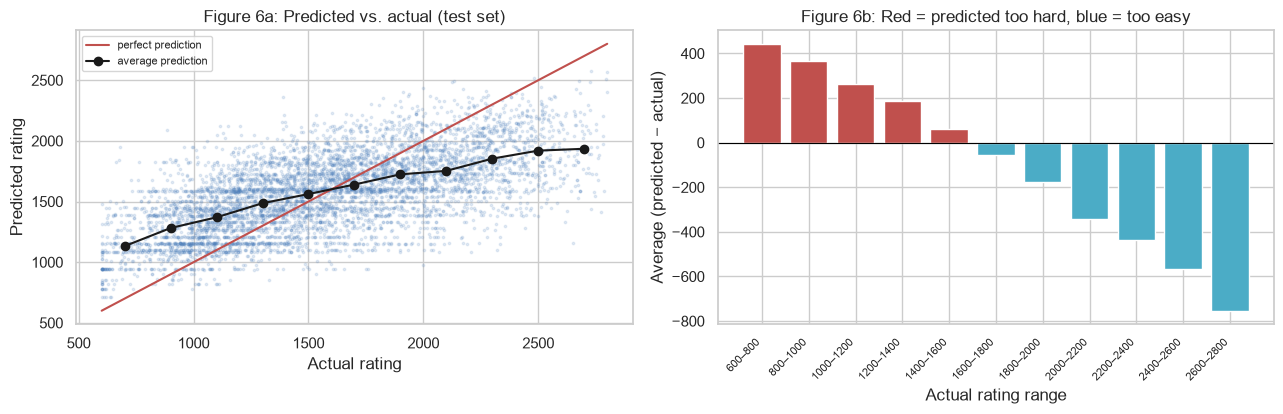

,600–800,800–1000,1000–1200,1200–1400,1400–1600,1600–1800,1800–2000,2000–2200,2200–2400,2400–2600,2600–2800
MAE,443.0,371.0,286.0,247.0,204.0,204.0,249.0,363.0,442.0,567.0,754.0
bias,443.0,367.0,264.0,185.0,62.0,-56.0,-175.0,-343.0,-437.0,-566.0,-754.0
puzzles,253.0,545.0,835.0,818.0,816.0,767.0,657.0,533.0,422.0,246.0,87.0


In [12]:
pred = pd.Series(forest.predict(X_test), index=idx_test)
band = pd.cut(y_test, bins=range(600, 3000, 200), include_lowest=True)
avg_pred = pred.groupby(band, observed=True).mean()
bias = (pred - y_test).groupby(band, observed=True).mean()
labels = [f"{round(iv.left)}–{round(iv.right)}" for iv in bias.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].scatter(y_test, pred, s=3, alpha=0.15, color="#4f81bd")
axes[0].plot([600, 2800], [600, 2800], color="#c0504d", label="perfect prediction")
axes[0].plot([iv.mid for iv in avg_pred.index], avg_pred.values, "ko-", label="average prediction")
axes[0].set_xlabel("Actual rating"); axes[0].set_ylabel("Predicted rating")
axes[0].set_title("Figure 6a: Predicted vs. actual (test set)"); axes[0].legend(fontsize=8)

axes[1].bar(labels, bias.values, color=["#c0504d" if b > 0 else "#4bacc6" for b in bias.values])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(range(len(labels))); axes[1].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
axes[1].set_xlabel("Actual rating range"); axes[1].set_ylabel("Average (predicted − actual)")
axes[1].set_title("Figure 6b: Red = predicted too hard, blue = too easy")
plt.tight_layout(); plt.show()

pd.DataFrame({"MAE": (pred - y_test).abs().groupby(band, observed=True).mean(),
              "bias": bias, "puzzles": band.value_counts().sort_index()}).set_axis(labels).round(0).T

**Observations:**
- **Predictions are squeezed toward the middle:** the black line is much flatter than the red one. The easiest puzzles (600–800) are predicted about 443 points too hard on average, and the hardest (2,600–2,800) about 754 points too easy. The model is most accurate in the middle (average error about 204 for puzzles rated 1,400–1,800).
- **Why:** six simple features can't tell many puzzles apart. The horizontal stripes in Figure 6a are groups of puzzles with identical feature values, which get identical predictions even though their real ratings differ a lot. For such a group, the best single guess is close to the group's average, so extreme puzzles get pulled toward the middle.
- So the model is useful for telling easy puzzles from hard ones, but not for pinpointing very easy or very hard ones.

### 7.2 Which features matter?

Two views: the **linear regression weights** (rating points per unit of each feature), and **permutation importance** for the random forest (how much the test error increases when one feature's values are shuffled, which breaks its link to the rating).

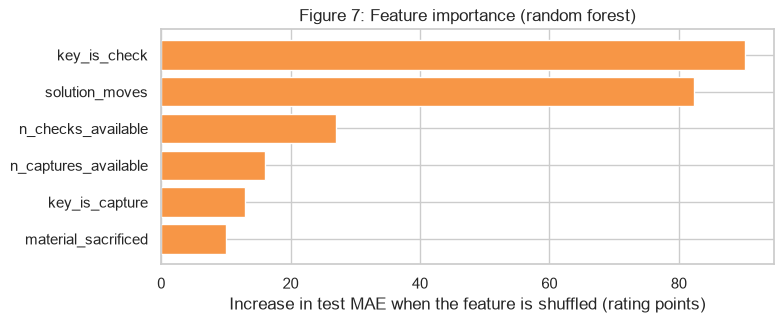

,linear weight (points per unit),forest: MAE increase when shuffled
key_is_check,-406.0,90.2
solution_moves,241.0,82.3
n_checks_available,54.0,27.0
n_captures_available,45.0,16.1
key_is_capture,-102.0,12.9
material_sacrificed,19.0,10.0


In [13]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(forest, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="neg_mean_absolute_error")
importance = pd.DataFrame({"linear weight (points per unit)": linear.coef_.round(0),
                           "forest: MAE increase when shuffled": perm.importances_mean.round(1)},
                          index=X.columns).sort_values("forest: MAE increase when shuffled")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(importance.index, importance["forest: MAE increase when shuffled"], color="#f79646")
ax.set_xlabel("Increase in test MAE when the feature is shuffled (rating points)")
ax.set_title("Figure 7: Feature importance (random forest)")
plt.tight_layout(); plt.show()
importance.iloc[::-1]

**Observations:**
- **Most important: whether the first move is a check** (shuffling it raises error by 90 points) **and solution length** (82). In the linear model, a check as the first move makes a puzzle about **406 points easier**, and each extra solution move adds about **241 points**.
- **Next: how many checks and captures are available** (27 and 16). In the linear model, each extra available check adds about 54 points and each available capture about 45. More forcing options means more possibilities for the solver to consider.
- **Smaller effects:** a capture as the first move (about 102 points easier than a quiet move) and material sacrificed (only 19 points per unit in the linear model, because the effect isn't a straight line; see Figure 5).
- Importance shows what the model relies on, not proof of what *causes* difficulty.

### 7.3 Supporting experiments

Three small experiments test the main claims above. All three use only the training and validation data; the test set is not touched again.

**Experiment 1: Is the random forest really better than linear regression?** The test set gives one number per model. Here we use 5-fold cross-validation on the training + validation data: the data is split into 5 parts, each model is trained on 4 parts and scored on the 5th, and this repeats 5 times. If the gap between the models is much larger than the variation between folds, it's real.

In [14]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in [("Linear regression", LinearRegression()),
                    ("Random forest", RandomForestRegressor(n_estimators=300, min_samples_leaf=best_leaf,
                                                            n_jobs=-1, random_state=RANDOM_STATE))]:
    scores = -cross_val_score(model, X_trval, y_trval, cv=cv, scoring="neg_mean_absolute_error")
    cv_rows.append({"model": name, "mean MAE": scores.mean().round(1), "std": scores.std().round(1),
                    "MAE in each fold": scores.round(1)})
pd.DataFrame(cv_rows)

,model,mean MAE,std,MAE in each fold
0,Linear regression,316.7,3.1,"[313.0, 315.0, 322.3, 315.8, 317.3]"
1,Random forest,306.6,2.6,"[302.8, 305.7, 310.9, 306.4, 307.3]"


**Observation:** the random forest beats linear regression in **every one of the 5 folds** (by 8–11 points each time), and on average 306.6 vs. 316.7. The gap (about 10 points) is several times larger than the fold-to-fold variation (standard deviation about 3), so the random forest's advantage is real, not luck from one particular split.

**Experiment 2: Is the limit the model or the features?** Many puzzles have exactly the same six feature values, and any model that uses only these features must give them all the same prediction. The best such prediction is the average rating of the group. So if we predict every training puzzle with its own group's average (which is unrealistically optimistic, since it uses the answers), we get the **best error any model could reach** with these six features on this data.

In [17]:
train_df = X_train.assign(Rating=y_train)
groups = train_df.groupby(list(X.columns)).Rating
best_possible = train_df.Rating - groups.transform("mean")

print(f"Distinct feature combinations: {groups.ngroups:,} for {len(train_df):,} training puzzles")
big = groups.agg(["size", "std"]).query("size >= 50")
print(f"Groups with 50+ identical puzzles: {len(big)}, covering {big['size'].sum() / len(train_df):.0%} of puzzles")
print(f"Typical spread of ratings inside such a group (median std): {big['std'].median():.0f} points")
print(f"Best possible MAE with these six features (optimistic, on training data): {best_possible.abs().mean():.1f}")
print(f"Random forest's MAE on the test set, for comparison: {mean_absolute_error(y_test, forest.predict(X_test)):.1f}")

Distinct feature combinations: 2,448 for 27,898 training puzzles
Groups with 50+ identical puzzles: 119, covering 64% of puzzles
Typical spread of ratings inside such a group (median std): 379 points
Best possible MAE with these six features (optimistic, on training data): 282.5
Random forest's MAE on the test set, for comparison: 305.5


**Observations:**
- The 27,898 training puzzles produce only **2,448 distinct combinations** of the six features. 119 combinations each cover 50 or more puzzles, together **64% of all puzzles**.
- Inside those groups, ratings still vary widely: a typical standard deviation of **379 points**, close to the spread of the whole dataset (about 500). Puzzles that look identical to the model can differ by more than 1,000 rating points.
- So even an ideal model using these six features can't get below an average error of about **283 points** (and that estimate is optimistic, because it was computed on the training data itself). The random forest's test error of 305.5 is already close to that limit.
- **Conclusion:** the remaining error comes mostly from the *features*, not the choice of model. A more complex model wouldn't help much; better results would need features that capture more about each puzzle. This also explains the squeezed predictions in Figure 6: large groups of different puzzles must share one prediction near their average.

## 8. Conclusions

**Summary:** using six features computed from each puzzle's position and solution, a random forest predicts Lichess puzzle ratings with an average error of about 306 rating points (R² 0.41), 26% better than always guessing the average. Linear regression is somewhat worse (318).

**What makes a puzzle hard:** a longer solution (about +300 points per move); a first move that isn't a check, with quiet moves the hardest; more checks and captures available to choose from; and sacrifices, especially pawn sacrifices.

**Limitations:**
- About 60% of the variation in difficulty is unexplained, and predictions are squeezed toward the average, so very easy and very hard puzzles are predicted poorly.
- The six features are the main bottleneck: even an ideal model using only these features couldn't get below an average error of about 283 points (Experiment 3).
- Only six features; about 40,000 puzzles from a 2022 snapshot of a database with millions.
- Ratings come from player attempts, so the labels contain some noise.
- The sacrifice feature counts material only, so it misses sacrifices made for position rather than material.

**Possible improvements:**
- More features: which piece moves first, Lichess's tactical theme tags (fork, pin, …), and features that measure how hard the right move is to *see* (e.g., how many other moves look almost as good, using a chess engine).
- More data from the full database.
- More flexible models (e.g., gradient boosting, or neural networks on the raw board given much more data).